# Task 2 - Oversampling / data synthesis (adult census)
AI use: Claude was used to guide the structure and understand some concepts that were quite confusing. I ran the code myself and checked the outputs.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sdv.single_table import GaussianCopulaSynthesizer
from sdv.metadata import Metadata
from sdv.sampling import Condition

In [2]:
df = pd.read_csv("../../../Datasets/adult.csv")   # use your own path
df = df.drop_duplicates()
df = df.replace("?", np.nan).dropna()

In [3]:
# test: what happens with the raw capital.gain column?
raw = pd.read_csv("../../../Datasets/adult.csv").drop_duplicates()
raw = raw.replace("?", np.nan).dropna()
raw = raw[["age", "education.num", "race", "capital.gain", "hours.per.week", "income"]].reset_index(drop=True)
conditions = [
    Condition(num_rows=314, column_values={"race": "Amer-Indian-Eskimo"}),
    Condition(num_rows=369, column_values={"race": "Other"}),
]

try:
    md_raw = Metadata.detect_from_dataframe(data=raw)
    syn_raw = GaussianCopulaSynthesizer(md_raw)
    syn_raw.fit(raw)
except AttributeError:
    md_raw = Metadata.detect_from_dataframes({"raw": raw})
    syn_raw = GaussianCopulaSynthesizer(md_raw)
    syn_raw.fit({"raw": raw})

syn_data = syn_raw.sample_from_conditions(conditions=conditions)
if isinstance(syn_data, dict):
    syn_data = syn_data["raw"]

print("zeros in capital.gain, real:     ", round((raw["capital.gain"] == 0).mean() * 100, 1), "%")
print("zeros in capital.gain, synthetic:", round((syn_data["capital.gain"] == 0).mean() * 100, 1), "%")
print("mean capital.gain, real / synthetic:", round(raw["capital.gain"].mean()), "/", round(syn_data["capital.gain"].mean()))

c:\D_DRIVE\AdvancedDataAnalytics\AdvancedDataAnalytics2026\.venv\Lib\site-packages\sdv\single_table\base.py:136: UserWarning: We strongly recommend saving the metadata using 'save_to_json' for replicability in future SDV versions.
  warnings.warn(
Sampling conditions: 100%|██████████| 683/683 [00:00<00:00, 15177.91it/s]

zeros in capital.gain, real:      91.6 %
zeros in capital.gain, synthetic: 2.2 %
mean capital.gain, real / synthetic: 1093 / 28242


* Why I ran this cell?
 'capital gain' is zero heavy (about 92% of rows are 0). Before choosing the columns for SDV, I wanted to check whether the GaussianCopula synthesizer can reproduce this kind of column.

* Result: It cannot. In the real data about 92% of 'capital gain' values are  and the mean is about 1100. In the synthetic rows about 3% are 0 and the mean is about 26,000. The synthetic values do not match the real distribution.

* Decision: I leave the raw 'capital.gain' and 'capital.loss' columns out of the SDV step. I use the yes/no flags 'has_gain' and 'has_loss' instead. This keeps the synthetic data relaistic. 

In [4]:
# SDV copes badly with the zero-heavy capital columns,
# so I replace them with yes/no flags
df["has_gain"] = np.where(df["capital.gain"] > 0, "yes", "no")
df["has_loss"] = np.where(df["capital.loss"] > 0, "yes", "no")

In [5]:
# keep the useful columns (drops fnlwgt, education, native.country)
df = df[["age", "workclass", "education.num", "marital.status", "occupation",
         "relationship", "race", "sex", "has_gain", "has_loss",
         "hours.per.week", "income"]].reset_index(drop=True)

In [6]:
print(df.shape)
print(df["race"].value_counts())

(30139, 12)
race
White                 25912
Black                  2816
Asian-Pac-Islander      894
Amer-Indian-Eskimo      286
Other                   231
Name: count, dtype: int64


### Step 2a

### Step 2b, histogram before

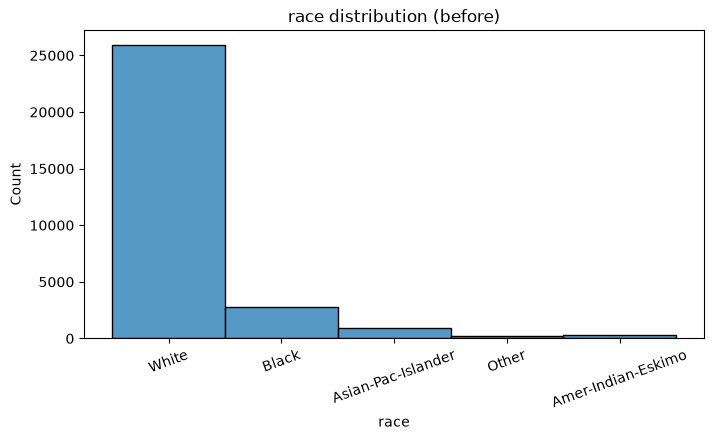

In [7]:
plt.figure(figsize=(8, 4))
sns.histplot(df, x="race")
plt.title("race distribution (before)")
plt.xticks(rotation=20)
plt.show()

In [8]:
# Let's let SDV metadata figure out what each column is containing.
metadata = Metadata.detect_from_dataframes(
    {"adult": df}
)


# Race is imbalanced: Amer-Indian-Eskimo and Other are very rare.
# We generate extra rows for both, so each ends up with 600 rows.
condition1 = Condition(
    num_rows=314,
    column_values={"race": "Amer-Indian-Eskimo"}
)
condition2 = Condition(
    num_rows=369,
    column_values={"race": "Other"}
)

# Set the synthetsizer and fit
synthesizer = GaussianCopulaSynthesizer(metadata)
synthesizer.fit({"adult": df})

# Extract synthesized data from those specific conditions
synthetic_data = synthesizer.sample_from_conditions(
    conditions=[condition1, condition2]
)

synthetic_data = synthetic_data["adult"] 

# Output dataframe
synthetic_data

c:\D_DRIVE\AdvancedDataAnalytics\AdvancedDataAnalytics2026\.venv\Lib\site-packages\sdv\single_table\base.py:136: UserWarning: We strongly recommend saving the metadata using 'save_to_json' for replicability in future SDV versions.
  warnings.warn(
Sampling conditions: 100%|██████████| 683/683 [00:00<00:00, 8202.18it/s]


,age,workclass,education.num,marital.status,occupation,relationship,race,sex,has_gain,has_loss,hours.per.week,income
0,45,Private,12,Never-married,Prof-specialty,Own-child,Amer-Indian-Eskimo,Male,no,no,53,>50K
1,25,Private,5,Divorced,Craft-repair,Not-in-family,Amer-Indian-Eskimo,Female,no,no,29,<=50K
2,46,Self-emp-inc,8,Widowed,Adm-clerical,Not-in-family,Amer-Indian-Eskimo,Male,no,no,37,<=50K
3,32,Private,8,Married-civ-spouse,Sales,Husband,Amer-Indian-Eskimo,Female,no,no,50,<=50K
4,44,Private,9,Married-civ-spouse,Sales,Unmarried,Amer-Indian-Eskimo,Female,no,no,43,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...
678,26,Private,10,Married-civ-spouse,Other-service,Husband,Other,Male,no,yes,18,<=50K
679,49,Private,8,Never-married,Handlers-cleaners,Unmarried,Other,Female,no,no,40,<=50K
680,27,Private,12,Married-civ-spouse,Craft-repair,Husband,Other,Male,no,no,33,<=50K
681,45,Private,12,Widowed,Machine-op-inspct,Not-in-family,Other,Male,no,no,43,>50K


In [9]:
df_combined = pd.concat([df, synthetic_data], ignore_index=True)
print(df.shape, synthetic_data.shape, df_combined.shape)
print(df_combined["race"].value_counts())

(30139, 12) (683, 12) (30822, 12)
race
White                 25912
Black                  2816
Asian-Pac-Islander      894
Other                   600
Amer-Indian-Eskimo      600
Name: count, dtype: int64


In [10]:
print(df["race"].value_counts(normalize=True).round(4) * 100)
print(df_combined["race"].value_counts(normalize=True).round(4) * 100)

race
White                 85.97
Black                  9.34
Asian-Pac-Islander     2.97
Amer-Indian-Eskimo     0.95
Other                  0.77
Name: proportion, dtype: float64
race
White                 84.07
Black                  9.14
Asian-Pac-Islander     2.90
Other                  1.95
Amer-Indian-Eskimo     1.95
Name: proportion, dtype: float64


In [11]:
df.describe()

,age,education.num,hours.per.week
count,30139.000000,30139.000000,30139.000000
mean,38.441720,10.122532,40.934703
std,13.131426,2.548738,11.978753
min,17.000000,1.000000,1.000000
25%,28.000000,9.000000,40.000000
50%,37.000000,10.000000,40.000000
75%,47.000000,13.000000,45.000000
max,90.000000,16.000000,99.000000


In [12]:
df_combined.describe()

,age,education.num,hours.per.week
count,30822.000000,30822.000000,30822.000000
mean,38.419408,10.119363,40.914152
std,13.136947,2.548755,11.972469
min,17.000000,1.000000,1.000000
25%,28.000000,9.000000,40.000000
50%,37.000000,10.000000,40.000000
75%,47.000000,12.000000,45.000000
max,90.000000,16.000000,99.000000


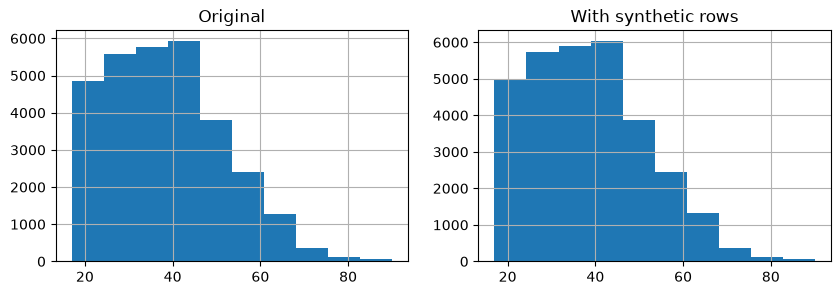

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
df["age"].hist(ax=axes[0])
df_combined["age"].hist(ax=axes[1])
axes[0].set_title("Original")
axes[1].set_title("With synthetic rows")
plt.show()